# Mohammed Moayed AlQurini - 2240007325 - 7MA2

# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

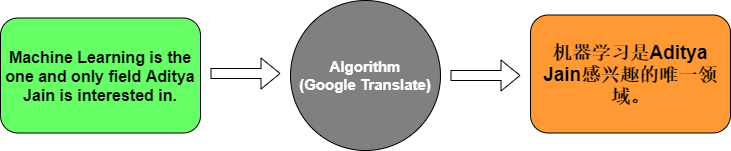

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
%pip install tensorflow pandas scikit-learn matplotlib nltk

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\moham\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/thumbnail?id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI&sz=w1000" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.1429 - loss: 2.4834 - val_accuracy: 0.0000e+00 - val_loss: 2.4846
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.5714 - loss: 2.4740 - val_accuracy: 0.0000e+00 - val_loss: 2.4860
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.5714 - loss: 2.4644 - val_accuracy: 0.0000e+00 - val_loss: 2.4875
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.5714 - loss: 2.4541 - val_accuracy: 0.0000e+00 - val_loss: 2.4892
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - accuracy: 0.5714 - loss: 2.4427 - val_accuracy: 0.0000e+00 - val_loss: 2.4911
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.5714 - loss: 2.4297 - val_accuracy: 0.0000e+00 - val_loss: 2.4933
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - accuracy: 0.5714 - loss: 2.4148 - val_accuracy: 0.0000e+00 - val_loss: 2.4958
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.5714 - loss: 2.3974 - val_acc

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 556ms/step
Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**1. Embedding layer**

The word index by itself is just a number (like 5 = "this") and it doesn't say anything about the meaning of the word. The embedding layer turns each index into a dense vector (64 numbers in this model). These vectors are learned during training so words that are used in similar ways end up with similar vectors.

**2. Encoder LSTM**

The encoder reads the English sentence word by word and keeps updating its hidden state. At the end it gives one vector that summarizes the whole input sentence (the context vector). Since `return_sequences` is not set, only the last output goes to the next layer.

**3. Decoder LSTM**

The decoder takes the context vector (repeated by `RepeatVector` for each French time step) and generates a sequence from it. Because `return_sequences=True` it gives an output at every time step, one for each French word position.

**4. Why softmax in the last layer**

At each time step the model has to choose one word from the whole French vocabulary. Softmax changes the raw scores into probabilities that add up to 1, then we take the word with the highest probability using `argmax`. It also works with `sparse_categorical_crossentropy` which needs probabilities.


### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

### Task 2 Solution

Steps:
1. Load the Kaggle dataset (`eng_-french.csv` has to be in the same folder as the notebook)
2. Clean the text and keep the shorter sentences only
3. Tokenize and pad both languages
4. Build the encoder-decoder LSTM (same idea as above but bigger)
5. Train, evaluate and try some translations

Note: I didn't use the full dataset (around 175k pairs) because it takes too long to train on my laptop, so I took a sample of short sentences.


In [8]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

df = pd.read_csv("eng_-french.csv")
print(df.shape)
df.head()


(175621, 2)


,English words/sentences,French words/sentences
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [9]:
# rename the columns because the original names are long
df = df.iloc[:, :2]
df.columns = ["english", "french"]

df = df.dropna().drop_duplicates()
print(df.shape)


(175621, 2)


In [10]:
def clean_text(text):
    text = str(text).lower()
    text = text.replace("\u2019", "'")
    text = re.sub(r"[^a-zàâäçéèêëîïôöùûüÿœæ' ]", " ", text)  # keep french letters
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["english"] = df["english"].apply(clean_text)
df["french"] = df["french"].apply(clean_text)

# keep short sentences only (max 8 words)
df["eng_len"] = df["english"].str.split().str.len()
df["frn_len"] = df["french"].str.split().str.len()
df = df[(df["eng_len"] <= 8) & (df["frn_len"] <= 8) & (df["eng_len"] > 0)]
print("after filtering:", df.shape)

df = df.sample(n=min(30000, len(df)), random_state=42).reset_index(drop=True)
print("sample size:", df.shape)
df[["english", "french"]].head(10)


after filtering: (133761, 4)
sample size: (30000, 4)


,english,french
0,have you been playing basketball all afternoon,as tu joué au basket toute l'après midi
1,it's not funny,ce n'est pas drôle
2,i don't know why i did that,je ne sais pas pourquoi j'ai fait cela
3,tom is wearing a new uniform,tom porte un nouvel uniforme
4,who invented the telephone,qui inventa le téléphone
5,that's not yours,ce n'est pas à vous
6,i'm sure that i can do that,je suis sûre de pouvoir le faire
7,have a nice weekend,bon week end
8,she's in the garden planting roses,elle plante des roses dans le jardin
9,thanks for coming on such short notice,merci d'être venu dans un délai si court


In [11]:
eng_tok = Tokenizer(filters="")
eng_tok.fit_on_texts(df["english"])
eng_seq = eng_tok.texts_to_sequences(df["english"])

frn_tok = Tokenizer(filters="")
frn_tok.fit_on_texts(df["french"])
frn_seq = frn_tok.texts_to_sequences(df["french"])

eng_vocab = len(eng_tok.word_index) + 1
frn_vocab = len(frn_tok.word_index) + 1
print("english vocab:", eng_vocab)
print("french vocab:", frn_vocab)

eng_maxlen = max(len(s) for s in eng_seq)
frn_maxlen = max(len(s) for s in frn_seq)

# padding at the end this time
X = pad_sequences(eng_seq, maxlen=eng_maxlen, padding="post")
y = pad_sequences(frn_seq, maxlen=frn_maxlen, padding="post")
print(X.shape, y.shape)


english vocab: 6881
french vocab: 11675
(30000, 8) (30000, 8)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(eng_maxlen,)),
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=128),
    tf.keras.layers.LSTM(256),                      # encoder
    tf.keras.layers.RepeatVector(frn_maxlen),
    tf.keras.layers.LSTM(256, return_sequences=True),  # decoder
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation="softmax"))
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.002),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 8, 128)         │       880,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 8, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 8, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 8, 11675)       │     3,000,475 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,800,795 (18.31 MB)

 Trainable params: 4,800,795 (18.31 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(X_train, np.expand_dims(y_train, -1),
                    epochs=25,
                    batch_size=64,
                    validation_split=0.1,
                    callbacks=[early_stop])


Epoch 1/25
338/338 ━━━━━━━━━━━━━━━━━━━━ 99s 283ms/step - accuracy: 0.3185 - loss: 5.3926 - val_accuracy: 0.3436 - val_loss: 5.0596
Epoch 2/25
338/338 ━━━━━━━━━━━━━━━━━━━━ 103s 305ms/step - accuracy: 0.3397 - loss: 4.9280 - val_accuracy: 0.3509 - val_loss: 4.8815
Epoch 3/25
338/338 ━━━━━━━━━━━━━━━━━━━━ 131s 271ms/step - accuracy: 0.3484 - loss: 4.8106 - val_accuracy: 0.3632 - val_loss: 4.8275
Epoch 4/25
338/338 ━━━━━━━━━━━━━━━━━━━━ 89s 264ms/step - accuracy: 0.3524 - loss: 4.7478 - val_accuracy: 0.3640 - val_loss: 4.7839
Epoch 5/25
338/338 ━━━━━━━━━━━━━━━━━━━━ 88s 260ms/step - accuracy: 0.3534 - loss: 4.6971 - val_accuracy: 0.3638 - val_loss: 4.7505
Epoch 6/25
338/338 ━━━━━━━━━━━━━━━━━━━━ 89s 262ms/step - accuracy: 0.3562 - loss: 4.6407 - val_accuracy: 0.3590 - val_loss: 4.7380
Epoch 7/25
338/338 ━━━━━━━━━━━━━━━━━━━━ 91s 268ms/step - accuracy: 0.3633 - loss: 4.5398 - val_accuracy: 0.3771 - val_loss: 4.5823
Epoch 8/25
338/338 ━━━━━━━━━━━━━━━━━━━━ 86s 255ms/step - accuracy: 0.3717 - loss:

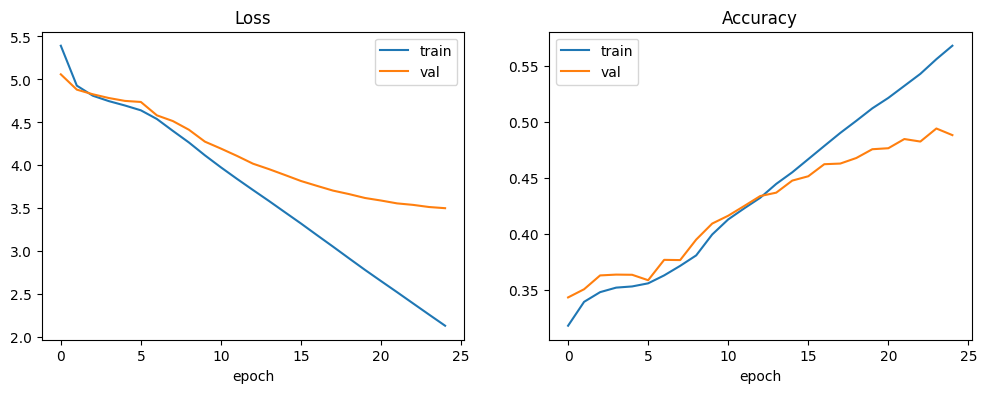

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy")
plt.xlabel("epoch")
plt.legend()

plt.show()


In [15]:
loss, acc = model.evaluate(X_test, np.expand_dims(y_test, -1))
print("Test loss:", loss)
print("Test accuracy:", acc)


188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 52ms/step - accuracy: 0.4863 - loss: 3.5253
Test loss: 3.5253472328186035
Test accuracy: 0.48629167675971985


The accuracy above also counts the padding zeros, and since short sentences have a lot of padding the number looks higher than it really is. So I also calculated the accuracy on the real words only (ignoring 0).


In [16]:
pred = np.argmax(model.predict(X_test, verbose=0), axis=-1)
mask = y_test != 0
word_acc = (pred[mask] == y_test[mask]).mean()
print("Accuracy without padding:", round(word_acc, 4))


Accuracy without padding: 0.287


In [17]:
def translate(sentence):
    sentence = clean_text(sentence)
    seq = eng_tok.texts_to_sequences([sentence])
    seq = pad_sequences(seq, maxlen=eng_maxlen, padding="post")
    p = model.predict(seq, verbose=0)
    ids = np.argmax(p, axis=-1)
    return frn_tok.sequences_to_texts(ids)[0]

# some sentences from the test set to compare with the real translation
for i in range(10):
    eng = eng_tok.sequences_to_texts([X_test[i]])[0]
    real = frn_tok.sequences_to_texts([y_test[i]])[0]
    print("EN  :", eng)
    print("Real:", real)
    print("Pred:", translate(eng))
    print("-" * 40)


EN  : i don't know you guys
Real: je ne vous connais pas
Pred: je ne sais pas pas
----------------------------------------
EN  : you were right to worry
Real: tu avais raison de t'inquiéter
Pred: tu devez toujours de à ce
----------------------------------------
EN  : give me a second
Real: donnez moi une seconde
Pred: donnez moi une
----------------------------------------
EN  : i thought we were going to your place
Real: je pensais que nous allions chez toi
Pred: je pense que nous nous un
----------------------------------------
EN  : he is lying through his teeth
Real: il ment outrageusement
Pred: il est le dans les la le
----------------------------------------
EN  : no one wants to talk about books anymore
Real: personne ne veut plus parler de livres
Pred: personne ne peut de pour avec
----------------------------------------
EN  : the project is not going well
Real: le projet ne se déroule pas bien
Pred: la n'est n'est pas pas pas
----------------------------------------
EN  : ex

In [18]:
# e-commerce style sentences (use case of the task)
test_sentences = ["this is a good price",
                  "i like this shirt",
                  "the delivery was fast",
                  "where is my order",
                  "thank you very much"]

for s in test_sentences:
    print(s, "->", translate(s))


this is a good price -> c'est une très difficile
i like this shirt -> j'aime cette cette
the delivery was fast -> le était était vite
where is my order -> où est mon sœur
thank you very much -> merci beaucoup


In [19]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

smooth = SmoothingFunction().method1
scores = []
for i in range(300):
    ref = frn_tok.sequences_to_texts([y_test[i]])[0].split()
    hyp = frn_tok.sequences_to_texts([pred[i]])[0].split()
    scores.append(sentence_bleu([ref], hyp, smoothing_function=smooth))

print("Average BLEU (300 test sentences):", round(np.mean(scores), 4))


Average BLEU (300 test sentences): 0.0979


### Discussion

- The model learns common short sentences well (greetings, simple "i am / he is" sentences) but makes mistakes with longer ones and rare words.
- The whole English sentence is squeezed into one vector, so the decoder loses some information. This is the main weakness of this simple encoder-decoder.
- Words not seen in training are ignored by the tokenizer, so they just disappear from the translation.
- For a real e-commerce company this model is not enough. Product names and reviews are longer and have special words. Better options would be adding attention, using teacher forcing, or using a pretrained transformer model (like MarianMT) and fine tuning it on product data.

### What I Learned

- How a seq2seq (encoder-decoder) model with LSTM works for translation and what each layer does.
- Preprocessing matters a lot: cleaning, keeping french accents, and limiting the sentence length made training much faster.
- `padding="post"` vs the default `pre` padding, and that Keras accuracy includes the padding so it can be misleading.
- BLEU score is a better way to judge translation than normal accuracy because the translation can be correct with different words.
- Training on the full dataset needs a lot of time and memory, so sampling is a practical trade-off.
